**Notebook 04: Practice-level regression**

This notebook tests what is associated with how much of a practice's SGLT2 prescribing was generic dapagliflozin between September 2025 and June 2026. It uses multiple linear regression at practice level, with robust standard errors and weights.

Input: `practice_level_regression_data.csv` (from notebook 03).

Outputs: `regression_summary.txt`, `regression_results.csv`, `regression_scatter_plots.png`, `regression_diagnostics.png`, `outlier_practices.csv`, `outlier_practices.png` and `model_comparison_results.csv`. Each run replaces the old versions.

Hypotheses (generic share is the outcome, so a positive coefficient means faster adoption): H1, more deprived practices adopt more slowly (negative IMD coefficient). H2, higher diabetes prevalence speeds adoption (positive coefficient). H3, larger list size speeds adoption (positive coefficient).

In [1]:
import importlib
import importlib.util
import subprocess
import sys

required = {'statsmodels': 'statsmodels', 'sklearn': 'scikit-learn'}   # module name: pip name

missing = [pip_name for module, pip_name in required.items()
           if importlib.util.find_spec(module) is None]

if missing:
    print('Installing:', ', '.join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
    importlib.invalidate_caches()
else:
    print('All required packages are already installed')

All required packages are already installed


**Step 1: Load libraries**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

print('Libraries loaded')

Libraries loaded


**Step 2: Load the practice-level data**

Each row is one GP practice. The outcome `avg_generic_share` is the mean monthly generic dapagliflozin share of SGLT2 items from Sep 2025 to Jun 2026. `avg_denominator` is the practice's average monthly SGLT2 items, used later as a weight.

In [3]:
df = pd.read_csv('practice_level_regression_data.csv')

print('Practices:', df.shape[0])
print('Missing values:', df.isnull().sum().sum())
print(df.groupby('icb').size())
print(df[['avg_generic_share', 'imd_practice', 'diabetes_prevalence',
          'list_size', 'avg_denominator']].describe().round(3).to_string())

Practices: 464
Missing values: 0
icb
Birmingham and Solihull      175
Black Country                170
Coventry and Warwickshire    119
dtype: int64
       avg_generic_share  imd_practice  diabetes_prevalence  list_size  avg_denominator
count            464.000       464.000              464.000    464.000          464.000
mean               0.638        34.503                0.096   7032.218          202.667
std                0.154        16.999                0.025   5681.477          159.605
min                0.117         1.136                0.014    570.000           12.200
25%                0.545        21.008                0.081   3641.750          106.675
50%                0.655        34.272                0.096   5465.000          154.700
75%                0.755        47.770                0.109   8511.000          252.400
max                0.937        75.274                0.177  46830.000         1282.100


**Step 3: Prepare the variables**

The variables are rescaled so the coefficients are easier to read. The outcome is in percentage points. IMD is shown per 10 points, diabetes prevalence per 1 percentage point, and list size per doubling (log base 2), because list size is strongly skewed.

In [4]:
df['y_pp'] = df['avg_generic_share'] * 100
df['imd_10'] = df['imd_practice'] / 10
df['imd_district_10'] = df['imd_district'] / 10
df['diabetes_pct'] = df['diabetes_prevalence'] * 100
df['log2_list_size'] = np.log2(df['list_size'])
df['change_pp'] = df['change_share'] * 100        # change in share, pp
df['pre_pp'] = df['pre_generic_share'] * 100      # Jan to Aug 2025 share, pp

print(df[['y_pp', 'imd_10', 'diabetes_pct', 'log2_list_size']].describe().round(2).to_string())

         y_pp  imd_10  diabetes_pct  log2_list_size
count  464.00  464.00        464.00          464.00
mean    63.75    3.45          9.57           12.46
std     15.37    1.70          2.52            0.93
min     11.67    0.11          1.42            9.15
25%     54.53    2.10          8.14           11.83
50%     65.54    3.43          9.57           12.42
75%     75.53    4.78         10.88           13.06
max     93.72    7.53         17.65           15.52


**Step 4: Plot each predictor against the outcome**

Each point is a practice, coloured by ICB. The line is a simple straight-line fit for reference only. The final model in Step 6 uses all three predictors together.

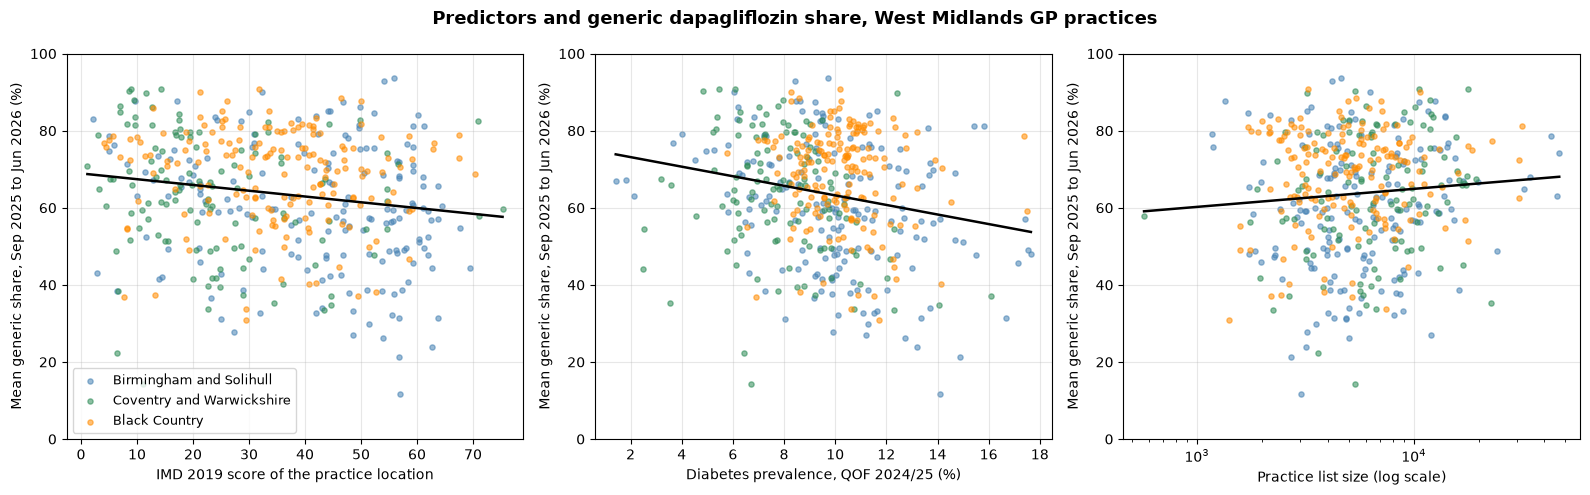

In [5]:
colours = {'Birmingham and Solihull': 'steelblue',
           'Coventry and Warwickshire': 'seagreen',
           'Black Country': 'darkorange'}

# (column, axis label, log scale?) - diabetes uses diabetes_pct from Step 3 so the axis is in %
panels = [('imd_practice', 'IMD 2019 score of the practice location', False),
          ('diabetes_pct', 'Diabetes prevalence, QOF 2024/25 (%)', False),
          ('list_size', 'Practice list size (log scale)', True)]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (col, label, log_x) in zip(axes, panels):
    for icb, c in colours.items():
        s = df[df['icb'] == icb]
        ax.scatter(s[col], s['y_pp'], alpha=0.55, color=c, s=14, label=icb)
    # straight line on the scale shown: list size is fitted on log2, as in the model
    x = np.log2(df[col]) if log_x else df[col]
    slope, intercept = np.polyfit(x, df['y_pp'], 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(2 ** xs if log_x else xs, intercept + slope * xs, color='black', linewidth=1.8)
    if log_x:
        ax.set_xscale('log')
    ax.set_xlabel(label)
    ax.set_ylabel('Mean generic share, Sep 2025 to Jun 2026 (%)')
    ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=9, loc='lower left')
plt.suptitle('Predictors and generic dapagliflozin share, West Midlands GP practices',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('regression_scatter_plots.png', dpi=300, bbox_inches='tight')
plt.show()

**Step 5: Check correlation between predictors**

If predictors are strongly related to each other, their separate effects are hard to tell apart. The variance inflation factor (VIF) measures this. Values below about 5 are usually fine.

In [6]:
predictors = ['imd_10', 'diabetes_pct', 'log2_list_size']

print('Correlation matrix:')
print(df[['y_pp'] + predictors].corr().round(2).to_string())

Xv = sm.add_constant(df[predictors])
vif = pd.DataFrame({'Variable': Xv.columns,
                    'VIF': [variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])]})
print('\nVariance inflation factors:')
print(vif[vif['Variable'] != 'const'].round(2).to_string(index=False))

Correlation matrix:
                y_pp  imd_10  diabetes_pct  log2_list_size
y_pp            1.00   -0.17         -0.20            0.08
imd_10         -0.17    1.00          0.51           -0.18
diabetes_pct   -0.20    0.51          1.00           -0.29
log2_list_size  0.08   -0.18         -0.29            1.00

Variance inflation factors:
      Variable  VIF
        imd_10 1.36
  diabetes_pct 1.44
log2_list_size 1.10


**Step 6: Main model (weighted least squares with HC3 standard errors)**

The model is: generic share (%) = constant + b1 x IMD + b2 x diabetes prevalence + b3 x log list size.

Each practice is weighted by its average monthly SGLT2 items. A practice with 12 items a month gives a very noisy share, while one with 1,000 items gives a stable one, so weighting stops small practices from driving the result. HC3 standard errors allow the spread of the residuals to differ between practices. The R-squared shown is the weighted one.

In [7]:
def fit_model(data, cols, weighted=True, extra=None):
    X = data[cols].copy()
    if extra is not None:
        X = pd.concat([X, extra], axis=1)
    X = sm.add_constant(X)
    if weighted:
        model = sm.WLS(data['y_pp'], X, weights=data['avg_denominator'])
    else:
        model = sm.OLS(data['y_pp'], X)
    return model.fit(cov_type='HC3', use_t=True)

main = fit_model(df, predictors)
print(main.summary())

                            WLS Regression Results                            
Dep. Variable:                   y_pp   R-squared:                       0.065
Model:                            WLS   Adj. R-squared:                  0.059
Method:                 Least Squares   F-statistic:                     6.576
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           0.000233
Time:                        00:08:24   Log-Likelihood:                -1953.5
No. Observations:                 464   AIC:                             3915.
Df Residuals:                     460   BIC:                             3932.
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const             59.9960     11.154      5.

**Step 7: Check the result with other model versions**

The main result is only trusted if it holds up under reasonable changes. Seven versions are fitted. Model 1 is the main model. Model 2 drops the weights. Model 3 replaces practice IMD with the district average. Models 4 and 5 add ICB and district dummies, to see how much of any effect is about where a practice sits. Models 6 and 7 deal with the fact that the outcome is a level of share. Model 6 uses the change in share from January to August 2025 to September 2025 to June 2026. Model 7 keeps the main outcome and adds the January to August 2025 share as a predictor. Adjusted R-squared is shown because Models 4, 5 and 7 add predictors.

In [8]:
icb_dummies = pd.get_dummies(df['icb'], drop_first=True).astype(float)
district_dummies = pd.get_dummies(df['district'], drop_first=True).astype(float)

df_pre = df.dropna(subset=['pre_generic_share']).copy()
df_change = df_pre.copy()
df_change['y_pp'] = df_change['change_pp']

models = {
    '1 Main (weighted, HC3)': (main, 'imd_10'),
    '2 Unweighted (HC3)': (fit_model(df, predictors, weighted=False), 'imd_10'),
    '3 District average IMD': (fit_model(df, ['imd_district_10', 'diabetes_pct', 'log2_list_size']),
                               'imd_district_10'),
    '4 With ICB dummies': (fit_model(df, predictors, extra=icb_dummies), 'imd_10'),
    '5 With district dummies': (fit_model(df, predictors, extra=district_dummies), 'imd_10'),
    '6 Change in share': (fit_model(df_change, predictors), 'imd_10'),
    '7 Adjusted for Jan to Aug 2025 share': (fit_model(df_pre, predictors + ['pre_pp']), 'imd_10'),
}

rows = []
for name, (res, imd_term) in models.items():
    terms = [(imd_term, 'IMD (per 10 points)'),
             ('diabetes_pct', 'Diabetes prevalence (per 1 point)'),
             ('log2_list_size', 'List size (per doubling)')]
    if 'pre_pp' in res.params:
        terms.append(('pre_pp', 'Jan to Aug 2025 share (per 1 point)'))
    for term, label in terms:
        rows.append({'Model': name, 'Variable': label,
                     'Coefficient (pp)': res.params[term],
                     'SE (HC3)': res.bse[term],
                     'p-value': res.pvalues[term],
                     'R-squared': res.rsquared,
                     'Adj R-squared': res.rsquared_adj,
                     'Practices': int(res.nobs)})

regression_results = pd.DataFrame(rows)
print(regression_results.round(4).to_string(index=False))

                               Model                            Variable  Coefficient (pp)  SE (HC3)  p-value  R-squared  Adj R-squared  Practices
              1 Main (weighted, HC3)                 IMD (per 10 points)           -0.7311    0.5436   0.1794     0.0646         0.0585        464
              1 Main (weighted, HC3)   Diabetes prevalence (per 1 point)           -1.0182    0.4426   0.0219     0.0646         0.0585        464
              1 Main (weighted, HC3)            List size (per doubling)            1.2426    0.7846   0.1139     0.0646         0.0585        464
                  2 Unweighted (HC3)                 IMD (per 10 points)           -0.7383    0.4718   0.1183     0.0470         0.0408        464
                  2 Unweighted (HC3)   Diabetes prevalence (per 1 point)           -0.9395    0.3258   0.0041     0.0470         0.0408        464
                  2 Unweighted (HC3)            List size (per doubling)            0.4178    0.7174   0.5606     0.04

**Step 8: Hypothesis table (main model)**

This compares each coefficient in the main model with the direction expected by the hypotheses. A hypothesis counts as supported only if the coefficient has the expected sign and p is below 0.05.

In [9]:
hypotheses = [('H1', 'Higher deprivation slows adoption', 'imd_10', -1),
              ('H2', 'Higher diabetes prevalence speeds adoption', 'diabetes_pct', 1),
              ('H3', 'Larger list size speeds adoption', 'log2_list_size', 1)]

def verdict(coef, p, expected_sign):
    if p < 0.05 and np.sign(coef) == expected_sign:
        return 'Supported'
    if p < 0.05:
        return 'Significant, opposite direction'
    return 'Not supported (not significant)'

h_rows = []
for code_, text, term, sign in hypotheses:
    coef, p = main.params[term], main.pvalues[term]
    h_rows.append({'Hypothesis': code_, 'Statement': text,
                   'Coefficient (pp)': coef, 'p-value': p,
                   'Result': verdict(coef, p, sign)})

hypothesis_table = pd.DataFrame(h_rows)
print(hypothesis_table.round(4).to_string(index=False))

Hypothesis                                  Statement  Coefficient (pp)  p-value                          Result
        H1          Higher deprivation slows adoption           -0.7311   0.1794 Not supported (not significant)
        H2 Higher diabetes prevalence speeds adoption           -1.0182   0.0219 Significant, opposite direction
        H3           Larger list size speeds adoption            1.2426   0.1139 Not supported (not significant)


**Step 9: Model diagnostics**

The left chart plots standardised residuals against fitted values. It should show no clear pattern. The right chart checks whether the residuals are roughly normal. The Breusch-Pagan test is run on the unweighted model. A small p-value means the residual spread is uneven, which is the reason for using HC3 standard errors.

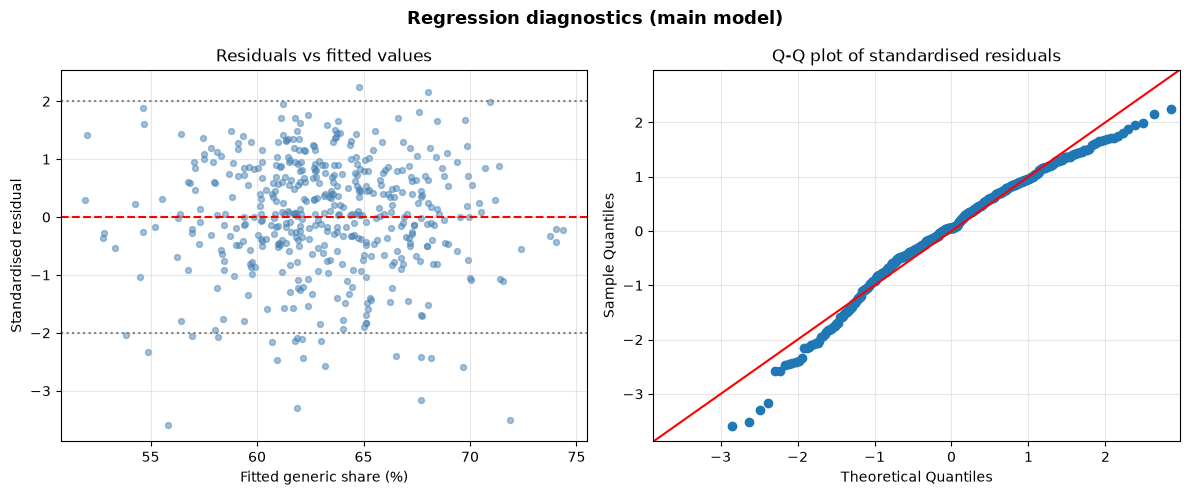

Breusch-Pagan test (unweighted model): LM = 6.74 , p = 0.0805


In [10]:
fitted = main.fittedvalues
z = main.resid_pearson

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(fitted, z, alpha=0.5, color='steelblue', s=18)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].axhline(2, color='grey', linestyle=':')
axes[0].axhline(-2, color='grey', linestyle=':')
axes[0].set_xlabel('Fitted generic share (%)')
axes[0].set_ylabel('Standardised residual')
axes[0].set_title('Residuals vs fitted values')
axes[0].grid(True, alpha=0.3)

sm.qqplot(z, line='45', ax=axes[1])
axes[1].set_title('Q-Q plot of standardised residuals')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Regression diagnostics (main model)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('regression_diagnostics.png', dpi=300, bbox_inches='tight')
plt.show()

unweighted = models['2 Unweighted (HC3)'][0]
lm, lm_p, f_stat, f_p = het_breuschpagan(unweighted.resid, unweighted.model.exog)
print('Breusch-Pagan test (unweighted model): LM =', round(lm, 2), ', p =', round(lm_p, 4))

**Step 10: Find practices that differ from what the model expects**

A practice is flagged when its standardised residual is above 2 or below -2, meaning its generic share is much higher or lower than the three predictors would suggest. A negative residual means slower adoption than expected.

This says nothing about why. The model has no information on clinical leadership, workforce or local ICB guidance. The chart marks the flagged practices without labels.

Flagged practices are shown only as counts by ICB and district. Their names and codes are saved in outlier_practices.csv for the author’s own use and are not published, in line with the ethics section of the dissertation (Section 3.7). A flag is a prompt for clinical review, not a judgement on a practice, and listing names publicly could be read as a league table of poor care.

flag
Within range            442
Slower than expected     20
Faster than expected      2
Name: count, dtype: int64

flag                       Faster than expected  Slower than expected  Within range
icb                                                                                
Birmingham and Solihull                       0                    13           162
Black Country                                 1                     1           168
Coventry and Warwickshire                     1                     6           112

Flagged practices by ICB and district (names are kept out of the notebook):
icb                        district           flag                
Birmingham and Solihull    Birmingham         Slower than expected    11
                           Solihull           Slower than expected     2
Black Country              Sandwell           Faster than expected     1
                           Walsall            Slower than expected     1
Coventry and Warwickshire  C

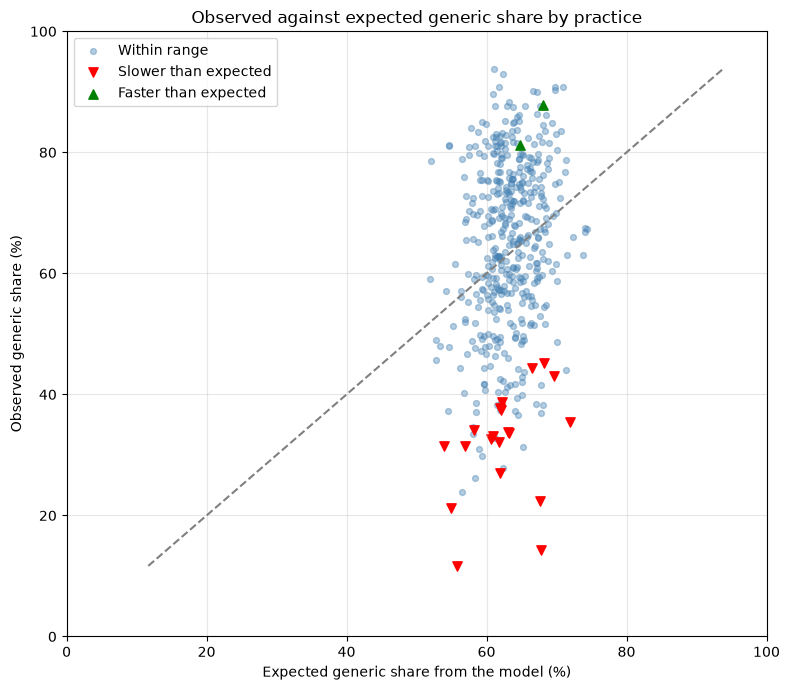

In [11]:
df['expected_pp'] = main.fittedvalues
df['residual_pp'] = main.resid
df['std_residual'] = main.resid_pearson
df['flag'] = np.where(df['std_residual'] < -2, 'Slower than expected',
              np.where(df['std_residual'] > 2, 'Faster than expected', 'Within range'))

print(df['flag'].value_counts())
print()
print(pd.crosstab(df['icb'], df['flag']).to_string())

outliers = df[df['flag'] != 'Within range'].sort_values('std_residual')
cols_out = ['org_id', 'org_name', 'icb', 'district', 'y_pp', 'expected_pp',
            'residual_pp', 'std_residual', 'avg_denominator', 'flag']
print('\nFlagged practices by ICB and district (names are kept out of the notebook):')
print(outliers.groupby(['icb', 'district', 'flag']).size().to_string())

fig, ax = plt.subplots(figsize=(8, 7))
normal = df[df['flag'] == 'Within range']
ax.scatter(normal['expected_pp'], normal['y_pp'], alpha=0.4, color='steelblue',
           s=18, label='Within range')
for label, c, m in [('Slower than expected', 'red', 'v'), ('Faster than expected', 'green', '^')]:
    s = df[df['flag'] == label]
    ax.scatter(s['expected_pp'], s['y_pp'], color=c, marker=m, s=45, label=label)
lo = df[['expected_pp', 'y_pp']].min().min()
hi = df[['expected_pp', 'y_pp']].max().max()
ax.plot([lo, hi], [lo, hi], color='grey', linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xlabel('Expected generic share from the model (%)')
ax.set_ylabel('Observed generic share (%)')
ax.set_title('Observed against expected generic share by practice')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('outlier_practices.png', dpi=300, bbox_inches='tight')
plt.show()

**Step 11: Second check with Isolation Forest**

Isolation Forest finds practices that are unusual across several variables at once. List size is left out this time, because including it mainly flags very large practices. The chosen 5% share of flagged practices is a setting, not a finding. The table shows how much this overlaps with the residual method.

In [12]:
iso = IsolationForest(contamination=0.05, random_state=42)
iso_features = ['y_pp', 'imd_practice', 'diabetes_pct']
df['iso_flag'] = iso.fit_predict(df[iso_features]) == -1

resid_set = set(df.loc[df['flag'] != 'Within range', 'org_id'])
iso_set = set(df.loc[df['iso_flag'], 'org_id'])

print('Flagged by Isolation Forest:', len(iso_set))
print('Flagged by residuals:', len(resid_set))
print('Flagged by both:', len(resid_set & iso_set))

Flagged by Isolation Forest: 24
Flagged by residuals: 22
Flagged by both: 6


**Step 12: Predictive check (cross-validation)**

This asks whether the predictors can predict the generic share of practices the model has not seen. Three sets of predictors are tried: the three practice characteristics only, the same plus ICB, and the same plus district. Six models are compared: a baseline that always predicts the average, linear regression, ridge, lasso, a random forest and gradient boosting.

Each score is the average R-squared from 5-fold cross-validation repeated 5 times with shuffling. A score near 0 means no predictive power, and a negative score means worse than guessing the average. With only a few predictors and light penalties, ridge and lasso give almost the same answer as linear regression. These models do not use the weights, so the check is a rough guide only.

In [13]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RepeatedKFold

y_ml = df['y_pp']
feature_sets = {
    'Practice only': df[predictors],
    'Plus ICB': pd.concat([df[predictors], icb_dummies], axis=1),
    'Plus district': pd.concat([df[predictors], district_dummies], axis=1),
}

cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)

ml_models = {
    'Mean only (baseline)': DummyRegressor(),
    'Linear regression': LinearRegression(),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=0.01)),
    'Random forest (depth 3)': RandomForestRegressor(n_estimators=200, max_depth=3,
                                                     min_samples_leaf=10, random_state=42),
    'Gradient boosting (depth 2)': GradientBoostingRegressor(n_estimators=100, max_depth=2,
                                                             learning_rate=0.05, subsample=0.8,
                                                             random_state=42),
}

cv_rows = []
for model_name, model in ml_models.items():
    row = {'Model': model_name}
    for set_name, X_set in feature_sets.items():
        scores = cross_val_score(model, X_set, y_ml, cv=cv, scoring='r2')
        row[set_name + ': mean R2'] = scores.mean()
        row[set_name + ': SD'] = scores.std()
    cv_rows.append(row)

model_comparison = pd.DataFrame(cv_rows)
print(model_comparison.round(3).to_string(index=False))

                      Model  Practice only: mean R2  Practice only: SD  Plus ICB: mean R2  Plus ICB: SD  Plus district: mean R2  Plus district: SD
       Mean only (baseline)                  -0.016              0.015             -0.016         0.015                  -0.016              0.015
          Linear regression                   0.017              0.042              0.080         0.074                   0.088              0.081
                      Ridge                   0.017              0.042              0.080         0.074                   0.088              0.081
                      Lasso                   0.017              0.042              0.080         0.074                   0.088              0.081
    Random forest (depth 3)                  -0.019              0.063              0.072         0.070                   0.029              0.061
Gradient boosting (depth 2)                  -0.052              0.077              0.045         0.075               

**Step 12b: Does tuning the random forest help?**

The forest above uses settings chosen in advance. This step checks whether other settings would do better. It tries 5 values of maximum depth and 4 values of minimum leaf size (20 settings) on the three practice characteristics, using 5-fold cross-validation repeated 3 times. If no setting beats the baseline, tuning cannot rescue the model, because the predictors carry too little signal.

In [14]:
cv_grid = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

grid_rows = []
for depth in [2, 3, 5, 8, None]:
    for leaf in [5, 10, 20, 40]:
        rf = RandomForestRegressor(n_estimators=200, max_depth=depth,
                                   min_samples_leaf=leaf, random_state=42)
        scores = cross_val_score(rf, df[predictors], y_ml, cv=cv_grid, scoring='r2')
        grid_rows.append({'Max depth': str(depth), 'Min leaf size': leaf,
                          'CV R2 mean': scores.mean()})

rf_grid = pd.DataFrame(grid_rows)
print(rf_grid.pivot(index='Max depth', columns='Min leaf size',
                    values='CV R2 mean').round(3).to_string())
print('\nBest setting:', round(rf_grid['CV R2 mean'].max(), 3),
      '| worst setting:', round(rf_grid['CV R2 mean'].min(), 3))

Min leaf size     5      10     20     40
Max depth                                
2             -0.010 -0.008 -0.002  0.005
3             -0.024 -0.022 -0.012  0.000
5             -0.055 -0.046 -0.025 -0.001
8             -0.093 -0.063 -0.027 -0.001
None          -0.107 -0.065 -0.027 -0.001

Best setting: 0.005 | worst setting: -0.107


**Step 13: Save results**

This saves the main model summary, the table comparing all seven model versions, the flagged practices and the cross-validation comparison. The random forest tuning results are in the printed output of Step 12b. The charts were saved in Steps 4, 9 and 10. These replace the old files with the same names.

In [15]:
with open('regression_summary.txt', 'w') as f:
    f.write(main.summary().as_text())

regression_results.to_csv('regression_results.csv', index=False)
flagged = df[df['flag'] != 'Within range'].sort_values('std_residual')
flagged[cols_out + ['iso_flag']].to_csv('outlier_practices.csv', index=False)
model_comparison.to_csv('model_comparison_results.csv', index=False)

print('Saved: regression_summary.txt, regression_results.csv, outlier_practices.csv,')
print('       model_comparison_results.csv, and the three charts')

Saved: regression_summary.txt, regression_results.csv, outlier_practices.csv,
       model_comparison_results.csv, and the three charts


**Acknowledgement of AI assistance**

This notebook was written by Mifta Mahmood with assistance from Claude (Anthropic), a generative AI assistant, which helped to write and debug the code. All code was run, checked and verified by the author, and the outputs shown are from the author's own runs. The final decisions on data, methods and interpretation are the author's own.